# 07. Monte Carlo를 이용한 옵션 가치평가

위험중립측도 $\mathbb{Q}$ 아래에서 주가경로를 생성하고 할인된 payoff의 평균으로 옵션가격을 추정합니다. 본문과 같은 Euler–Maruyama 이산화, 경로 수, 시간 단계 수와 seed를 사용합니다.

**사용 방법**

- 이 노트북의 셀을 위에서부터 순서대로 실행하세요. 앞 장을 실행할 필요는 없습니다.
- 표와 그림, 수치 출력은 실제 실행 결과입니다. 함수 정의 셀은 출력이 없어도 정상입니다.
- `강의록의 출력 예시`는 원문에 적힌 비교용 텍스트이며, 실제 실행 출력과 구분합니다.
- 50만 경로 비교와 1,000단계 실험은 다른 셀보다 시간이 걸립니다. 난수 seed가 같으면 같은 환경에서 재현할 수 있고, 실행시간은 컴퓨터마다 달라집니다.

$$\widehat V_0=e^{-rT}\frac{1}{N}\sum_{i=1}^N H^{(i)},\qquad
\widehat{\mathrm{SE}}=\frac{s(e^{-rT}H)}{\sqrt N}.$$

경로 수 $N$은 sampling error에, 시간 단계 수 $M$은 discretization error에 영향을 줍니다. 표시하는 95% 구간은 표본오차에 대한 근사 구간이며 이산화 편향까지 포함하지 않습니다.

In [1]:
%matplotlib inline

## 실습 준비

NumPy는 난수와 배열 계산, pandas는 결과표, Matplotlib은 그래프에 사용합니다.

### 이번 장에서 사용할 라이브러리 불러오기

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### 가격·만기·계산 규모 설정

In [3]:
spot = 100.0
strike = 100.0
maturity = 1.0
n_paths = 100_000
n_steps = 252

## 소수의 주가경로 생성하기

Euler–Maruyama에서는 $S_{n+1}=S_n+(r-q)S_n\Delta t+\sigma S_n\sqrt{\Delta t}Z_n$을 사용합니다. 아래 함수는 `(시간, 경로)` 순서의 2차원 배열을 반환합니다. 먼저 20개의 경로를 그립니다.

### Euler–Maruyama 주가경로를 저장하는 함수

행은 시간, 열은 경로입니다. 부호가 잘못된 Euler 주가가 생기면 함수를 중단하여 시간격자 문제를 알립니다.

In [4]:
def simulate_gbm_paths(
    spot,
    maturity,
    rate,
    volatility,
    n_paths,
    n_steps,
    seed,
    dividend_yield=0.0,
):
    spot = float(spot)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    counts = (("n_paths", n_paths, 1), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)

    parameters = [spot, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or maturity <= 0.0:
        raise ValueError("spot and maturity must be positive")
    if volatility < 0.0:
        raise ValueError("volatility must be nonnegative")
    if n_paths <= 0 or n_steps <= 0:
        raise ValueError("n_paths and n_steps must be positive")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    time_grid = np.linspace(0.0, maturity, num=n_steps + 1)

    rng = np.random.default_rng(seed)
    paths = np.empty((n_steps + 1, n_paths), dtype=float)
    paths[0, :] = spot

    for step in range(n_steps):
        current_stock = paths[step, :]
        z = rng.standard_normal(n_paths)
        drift = (rate - dividend_yield) * current_stock * dt
        diffusion = volatility * current_stock * sqrt_dt * z
        next_stock = current_stock + drift + diffusion

        if np.any(next_stock <= 0.0):
            raise RuntimeError("Euler scheme produced a nonpositive stock price")

        paths[step + 1, :] = next_stock

    return time_grid, paths

### 20개의 주가경로 생성하기

In [5]:
time_grid, sample_paths = simulate_gbm_paths(
    spot=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    n_paths=20,
    n_steps=252,
    seed=2026,
)

print(sample_paths.shape)
print(sample_paths.dtype)

(253, 20)
float64


**강의록 Listing 5**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
(253, 20)
float64
```

### 생성한 주가경로 그리기

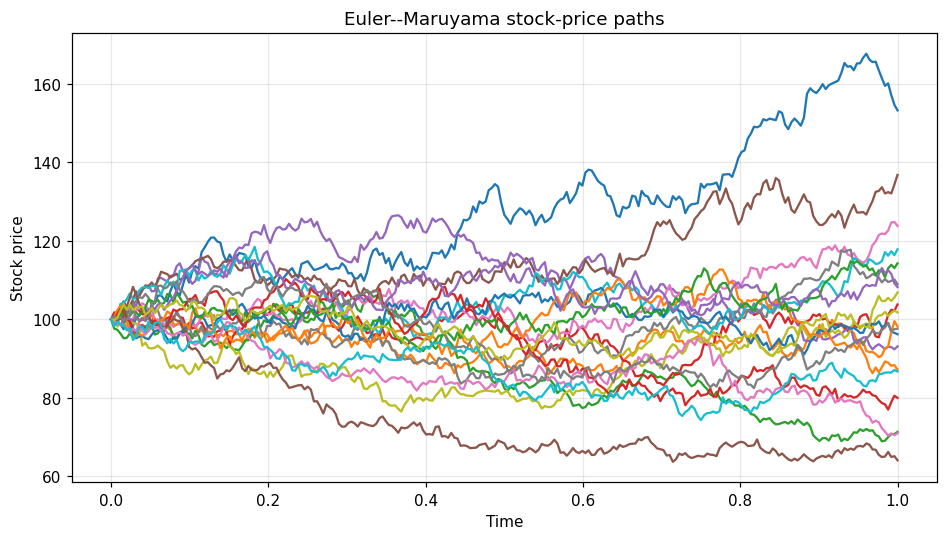

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
ax.plot(time_grid, sample_paths)
ax.set_title("Euler--Maruyama stock-price paths")
ax.set_xlabel("Time")
ax.set_ylabel("Stock price")
ax.grid(True, alpha=0.3)
plt.show()

## 유럽형 옵션의 Monte Carlo 가격

유럽형 payoff에는 만기주가만 필요하므로 현재 주가 배열을 갱신하는 방식으로 메모리를 절약합니다. 표준오차는 할인된 payoff의 표본표준편차로 계산합니다.

### 콜옵션과 풋옵션 payoff 함수

In [7]:
def option_payoff(terminal_stock, strike, option_type):
    terminal_stock = np.asarray(terminal_stock, dtype=float)
    strike = float(strike)
    option_type = str(option_type).lower()

    if option_type == "call":
        return np.maximum(terminal_stock - strike, 0.0)
    if option_type == "put":
        return np.maximum(strike - terminal_stock, 0.0)

    raise ValueError("option_type must be call or put")

### 만기주가만 생성하는 메모리 절약형 함수

현재 주가만 보관하므로 경로 수가 커져도 전체 경로 배열이 필요하지 않습니다.

In [8]:
def simulate_gbm_terminal(
    spot,
    maturity,
    rate,
    volatility,
    n_paths,
    n_steps,
    seed,
    dividend_yield=0.0,
):
    spot = float(spot)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    counts = (("n_paths", n_paths, 1), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)

    parameters = [spot, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or maturity <= 0.0:
        raise ValueError("spot and maturity must be positive")
    if volatility < 0.0:
        raise ValueError("volatility must be nonnegative")
    if n_paths <= 0 or n_steps <= 0:
        raise ValueError("n_paths and n_steps must be positive")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    rng = np.random.default_rng(seed)
    stock = np.full(n_paths, spot, dtype=float)

    for _ in range(n_steps):
        z = rng.standard_normal(n_paths)
        drift = (rate - dividend_yield) * stock * dt
        diffusion = volatility * stock * sqrt_dt * z
        stock = stock + drift + diffusion

        if np.any(stock <= 0.0):
            raise RuntimeError("Euler scheme produced a nonpositive stock price")

    return stock

### 유럽형 옵션의 Monte Carlo 가격함수

In [9]:
def monte_carlo_european_option(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    n_paths,
    n_steps,
    seed,
    option_type="call",
    dividend_yield=0.0,
):
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)

    parameters = [strike, maturity, rate]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")
    if isinstance(n_paths, (bool, np.bool_)):
        raise TypeError("n_paths must not be bool")
    if not isinstance(n_paths, (int, np.integer)):
        raise TypeError("n_paths must be an integer")
    if n_paths < 2:
        raise ValueError("at least two paths are required for a standard error")
    n_paths = int(n_paths)

    terminal_stock = simulate_gbm_terminal(
        spot=spot,
        maturity=maturity,
        rate=rate,
        volatility=volatility,
        n_paths=n_paths,
        n_steps=n_steps,
        seed=seed,
        dividend_yield=dividend_yield,
    )

    payoff = option_payoff(terminal_stock, strike, option_type)
    discounted_payoff = np.exp(-rate * maturity) * payoff

    price = float(discounted_payoff.mean())
    standard_error = float(discounted_payoff.std(ddof=1) / np.sqrt(n_paths))
    lower = price - 1.96 * standard_error
    upper = price + 1.96 * standard_error

    return {
        "price": price,
        "standard_error": standard_error,
        "lower": lower,
        "upper": upper,
    }

### 유럽형 콜옵션의 Monte Carlo 가격 계산

In [10]:
call_result = monte_carlo_european_option(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

for name, value in call_result.items():
    print(f"{name}: {value:.6f}")

price: 9.459295
standard_error: 0.044748
lower: 9.371588
upper: 9.547002


**강의록 Listing 11**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
price: 9.459295
standard_error: 0.044748
lower: 9.371588
upper: 9.547002
```

## 같은 경로를 이용한 구현 검산

콜과 풋에 동일한 만기주가를 사용합니다. 두 payoff의 차이가 만기주가에서 행사가격을 뺀 값과 같은지를 표본 수준에서 확인합니다. 표본평균 주가가 이론적 기대주가와 정확히 같을 필요는 없습니다.

### 같은 경로를 이용한 콜과 풋의 관계 확인

In [11]:
terminal_stock = simulate_gbm_terminal(
    spot=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

discount = np.exp(-0.03)
call_price = discount * option_payoff(terminal_stock, 100.0, "call").mean()
put_price = discount * option_payoff(terminal_stock, 100.0, "put").mean()
right_side = discount * (terminal_stock.mean() - 100.0)

print(call_price)
print(put_price)
print(call_price - put_price)
print(right_side)
print(np.isclose(call_price - put_price, right_side))

9.459294548289563
6.469874271133282
2.989420277156281
2.989420277156261
True


**강의록 Listing 13**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
9.459294548289565
6.469874271133281
2.9894202771562837
2.9894202771562886
True
```

## 경로 수와 시간 단계 수의 영향

경로 수를 늘리면 보통 표준오차가 $N^{-1/2}$ 정도로 작아집니다. 추정가격 자체가 단조롭게 움직일 필요는 없습니다. 단계 수 실험은 시간 이산화의 영향도 함께 보여 줍니다.

### 경로 수에 따른 가격과 standard error 비교

최대 500,000경로를 실제 계산합니다. 앞의 100,000경로 결과가 표에서 재현되는지도 확인하세요.

In [12]:
path_counts = [10_000, 50_000, 100_000, 500_000]
records = []

for n_paths in path_counts:
    result = monte_carlo_european_option(
        spot=100.0,
        strike=100.0,
        maturity=1.0,
        rate=0.03,
        volatility=0.20,
        n_paths=n_paths,
        n_steps=252,
        seed=2026,
    )

    records.append(
        {
            "n_paths": n_paths,
            "price": result["price"],
            "standard_error": result["standard_error"],
        }
    )

path_table = pd.DataFrame(records)
print(path_table)

   n_paths     price  standard_error
0    10000  9.526397        0.143557
1    50000  9.393549        0.062707
2   100000  9.459295        0.044748
3   500000  9.445061        0.019997


**강의록 Listing 15**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
   n_paths     price  standard_error
0    10000  9.526397        0.143557
1    50000  9.393549        0.062707
2   100000  9.459295        0.044748
3   500000  9.445061        0.019997
```

### 경로 수와 standard error의 관계 그리기

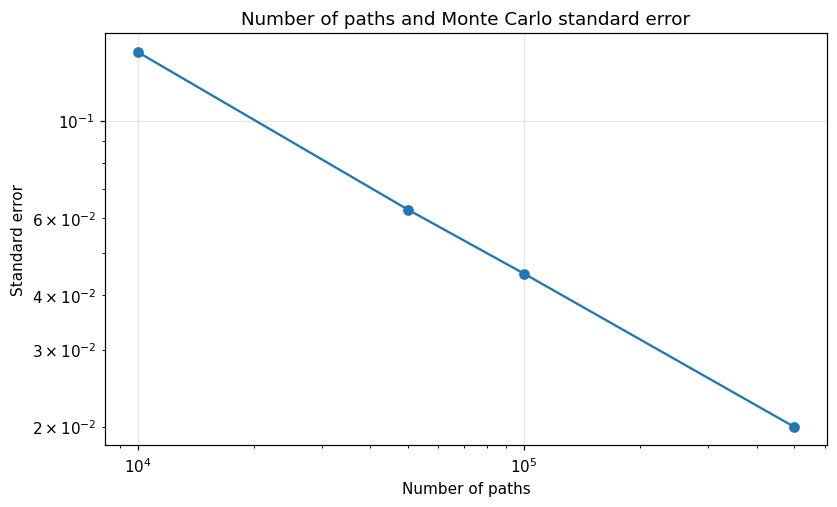

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), layout="constrained")
ax.plot(path_table["n_paths"], path_table["standard_error"], marker="o")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Number of paths and Monte Carlo standard error")
ax.set_xlabel("Number of paths")
ax.set_ylabel("Standard error")
ax.grid(True, alpha=0.3)
plt.show()

### 시간 단계 수에 따른 가격 비교

경로 수 100,000개는 고정하고 시간 단계 수를 12, 52, 252, 1,000으로 바꿉니다.

In [14]:
step_counts = [12, 52, 252, 1000]
records = []

for n_steps in step_counts:
    result = monte_carlo_european_option(
        spot=100.0,
        strike=100.0,
        maturity=1.0,
        rate=0.03,
        volatility=0.20,
        n_paths=100_000,
        n_steps=n_steps,
        seed=2026,
    )

    records.append(
        {
            "n_steps": n_steps,
            "price": result["price"],
            "standard_error": result["standard_error"],
        }
    )

step_table = pd.DataFrame(records)
print(step_table)

   n_steps     price  standard_error
0       12  9.444097        0.044259
1       52  9.394817        0.044459
2      252  9.459295        0.044748
3     1000  9.493894        0.044880


## 산술평균 아시안 콜옵션

각 단계의 주가를 누적하여 평균을 계산합니다. 이 예제는 최초 주가를 평균에서 제외하고 이후 관측값을 사용합니다. 전체 경로를 저장하지 않고 현재주가와 누적합만 유지합니다.

### 산술평균 아시안 콜옵션의 Monte Carlo 가격함수

관측 시점이 바뀌면 아시안 payoff 자체도 바뀐다는 점에 주의하세요.

In [15]:
def monte_carlo_asian_call(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    n_paths,
    n_steps,
    seed,
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if volatility < 0.0 or n_paths <= 0 or n_steps <= 0:
        raise ValueError("volatility, n_paths and n_steps are invalid")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    rng = np.random.default_rng(seed)

    stock = np.full(n_paths, spot, dtype=float)
    running_sum = np.zeros(n_paths, dtype=float)

    for _ in range(n_steps):
        z = rng.standard_normal(n_paths)
        drift = (rate - dividend_yield) * stock * dt
        diffusion = volatility * stock * sqrt_dt * z
        stock = stock + drift + diffusion

        if np.any(stock <= 0.0):
            raise RuntimeError("Euler scheme produced a nonpositive stock price")

        running_sum += stock

    average_stock = running_sum / n_steps
    payoff = np.maximum(average_stock - strike, 0.0)
    discounted_payoff = np.exp(-rate * maturity) * payoff

    price = float(discounted_payoff.mean())
    standard_error = float(discounted_payoff.std(ddof=1) / np.sqrt(n_paths))
    return price, standard_error

### 산술평균 아시안 콜옵션 평가 예

In [16]:
asian_price, asian_se = monte_carlo_asian_call(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

print(f"Asian call price: {asian_price:.6f}")
print(f"standard error: {asian_se:.6f}")

Asian call price: 5.305444
standard error: 0.024491


**강의록 Listing 20**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
Asian call price: 5.305444
standard error: 0.024491
```

## 실행시간과 재현 가능한 난수

`time.perf_counter()`로 실제 계산시간을 측정합니다. 난수 생성기는 함수 호출 시 한 번 만들고 시간 반복문 안에서는 새 난수만 생성합니다.

### Monte Carlo 함수의 실행시간 측정

In [17]:
start = time.perf_counter()

result = monte_carlo_european_option(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

elapsed = time.perf_counter() - start
print(f"price: {result['price']:.6f}")
print(f"elapsed seconds: {elapsed:.4f}")

price: 9.459295
elapsed seconds: 0.3653


## 선택 학습: CEV와 Heston Monte Carlo

CEV는 주가에 따른 변동성, Heston은 확률적으로 변하는 분산을 도입합니다. 아래 CEV와 Heston 코드는 음의 근삿값을 0으로 투영하는 규칙을 사용합니다. 본문의 100,000경로와 252단계를 유지합니다.

### CEV 모형의 Euler–Maruyama Monte Carlo 가격함수

CEV의 확산계수는 기준주가에서 변동성이 sigma0가 되도록 정규화합니다.

In [18]:
def monte_carlo_cev_option(
    spot,
    strike,
    maturity,
    rate,
    sigma0,
    beta,
    n_paths,
    n_steps,
    seed,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    sigma0 = float(sigma0)
    beta = float(beta)
    dividend_yield = float(dividend_yield)
    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)

    parameters = [spot, strike, maturity, rate, sigma0, beta, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if sigma0 <= 0.0 or not 0.0 < beta <= 1.0:
        raise ValueError("require sigma0 > 0 and 0 < beta <= 1")
    if n_paths <= 0 or n_steps <= 0:
        raise ValueError("n_paths and n_steps must be positive")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    diffusion_scale = sigma0 * spot ** (1.0 - beta)

    rng = np.random.default_rng(seed)
    stock = np.full(n_paths, spot, dtype=float)

    for _ in range(n_steps):
        z = rng.standard_normal(n_paths)
        positive_stock = np.maximum(stock, 0.0)
        drift = (rate - dividend_yield) * positive_stock * dt
        diffusion = diffusion_scale * positive_stock**beta * sqrt_dt * z
        stock = np.maximum(positive_stock + drift + diffusion, 0.0)

    payoff = option_payoff(stock, strike, option_type)
    discounted_payoff = np.exp(-rate * maturity) * payoff
    price = float(discounted_payoff.mean())
    standard_error = float(discounted_payoff.std(ddof=1) / np.sqrt(n_paths))
    return price, standard_error

### CEV 유럽형 콜옵션 평가 예

In [19]:
cev_price, cev_se = monte_carlo_cev_option(
    spot=100.0,
    strike=110.0,
    maturity=1.0,
    rate=0.03,
    sigma0=0.20,
    beta=0.80,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

print(f"CEV call price: {cev_price:.6f}")
print(f"standard error: {cev_se:.6f}")

CEV call price: 5.255808
standard error: 0.033419


**강의록 Listing 24**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
CEV call price: 5.255808
standard error: 0.033419
```

### 상관계수 rho를 갖는 두 정규충격 만들기

두 독립 표준정규난수를 결합하여 상관된 충격을 만듭니다.

In [20]:
rng = np.random.default_rng(2026)
z_variance = rng.standard_normal(100_000)
z_independent = rng.standard_normal(100_000)

correlation = -0.70
z_stock = correlation * z_variance
z_stock += np.sqrt(1.0 - correlation**2) * z_independent

sample_correlation = np.corrcoef(z_stock, z_variance)[0, 1]
print(sample_correlation)

-0.6992561573281783


**강의록 Listing 26**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
-0.6992561573281783
```

### Heston 모형의 projected Euler–Maruyama 가격함수

주가와 분산을 같은 시간 단계에서 함께 갱신합니다. 초기분산 0.04는 초기변동성 0.20에 해당합니다.

In [21]:
def monte_carlo_heston_option(
    spot,
    strike,
    maturity,
    rate,
    initial_variance,
    kappa,
    theta,
    vol_of_variance,
    correlation,
    n_paths,
    n_steps,
    seed,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    initial_variance = float(initial_variance)
    kappa = float(kappa)
    theta = float(theta)
    vol_of_variance = float(vol_of_variance)
    correlation = float(correlation)
    dividend_yield = float(dividend_yield)
    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)

    parameters = [spot, strike, maturity, rate, initial_variance, kappa, theta, vol_of_variance, correlation, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if initial_variance < 0.0 or theta < 0.0 or vol_of_variance < 0.0:
        raise ValueError("variance parameters must be nonnegative")
    if kappa < 0.0 or n_paths <= 0 or n_steps <= 0:
        raise ValueError("kappa must be nonnegative; counts must be positive")
    if not -1.0 <= correlation <= 1.0:
        raise ValueError("correlation must be between -1 and 1")

    dt = maturity / n_steps
    sqrt_dt = np.sqrt(dt)
    independent_scale = np.sqrt(1.0 - correlation**2)

    rng = np.random.default_rng(seed)
    stock = np.full(n_paths, spot, dtype=float)
    variance = np.full(n_paths, initial_variance, dtype=float)

    for _ in range(n_steps):
        z_variance = rng.standard_normal(n_paths)
        z_independent = rng.standard_normal(n_paths)
        z_stock = correlation * z_variance + independent_scale * z_independent

        positive_variance = np.maximum(variance, 0.0)
        sqrt_variance = np.sqrt(positive_variance)

        next_stock = stock + (rate - dividend_yield) * stock * dt
        next_stock += sqrt_variance * stock * sqrt_dt * z_stock

        next_variance = variance + kappa * (theta - positive_variance) * dt
        next_variance += vol_of_variance * sqrt_variance * sqrt_dt * z_variance

        stock = np.maximum(next_stock, 0.0)
        variance = np.maximum(next_variance, 0.0)

    payoff = option_payoff(stock, strike, option_type)
    discounted_payoff = np.exp(-rate * maturity) * payoff
    price = float(discounted_payoff.mean())
    standard_error = float(discounted_payoff.std(ddof=1) / np.sqrt(n_paths))

    return price, standard_error

### Heston 유럽형 콜옵션 평가 예

In [22]:
heston_price, heston_se = monte_carlo_heston_option(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    initial_variance=0.04,
    kappa=2.0,
    theta=0.04,
    vol_of_variance=0.30,
    correlation=-0.70,
    n_paths=100_000,
    n_steps=252,
    seed=2026,
)

print(f"Heston call price: {heston_price:.6f}")
print(f"standard error: {heston_se:.6f}")

Heston call price: 9.278141
standard error: 0.036787


**강의록 Listing 29**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
Heston call price: 9.278141
standard error: 0.036787
```

## 보충 실습 1: 유럽형 풋옵션

강의록 기본 연습 1의 입력을 그대로 사용합니다. 결과의 95% 구간은 Monte Carlo 표본오차에 대한 근사 구간입니다.

In [23]:
put_exercise = monte_carlo_european_option(
    spot=100.0,
    strike=105.0,
    maturity=0.5,
    rate=0.03,
    volatility=0.25,
    n_paths=100_000,
    n_steps=126,
    seed=2026,
    option_type="put",
    dividend_yield=0.01,
)
pd.DataFrame([put_exercise])

,price,standard_error,lower,upper
0,9.298947,0.03362,9.233051,9.364843


## 보충 실습 2: 변동성이 클 때의 Euler 시간격자

강의록 기본 연습 3의 변동성 0.80, 단계 수 1·4·12·52·252를 사용합니다. 명시되지 않은 값은 본문 예제인 주가 100, 만기 1년, 금리 0.03, 100,000경로, seed 2026으로 둡니다.

음의 주가를 삭제하거나 고치지 않습니다. 원래 함수가 발생시키는 `RuntimeError`만 이 실험에서 잡아서 표로 보여 주므로 뒤의 셀도 실행할 수 있습니다. 표의 성공은 해당 난수표본에서 검사를 통과했다는 뜻입니다.

In [24]:
grid_rows = []
for exercise_steps in [1, 4, 12, 52, 252]:
    try:
        terminal = simulate_gbm_terminal(
            spot=100.0,
            maturity=1.0,
            rate=0.03,
            volatility=0.80,
            n_paths=100_000,
            n_steps=exercise_steps,
            seed=2026,
        )
    except RuntimeError as error:
        grid_rows.append({"n_steps": exercise_steps, "status": str(error), "minimum_terminal": np.nan})
    else:
        grid_rows.append({"n_steps": exercise_steps, "status": "검사 통과", "minimum_terminal": float(terminal.min())})
pd.DataFrame(grid_rows)

,n_steps,status,minimum_terminal
0,1,Euler scheme produced a nonpositive stock price,NaN
1,4,Euler scheme produced a nonpositive stock price,NaN
2,12,Euler scheme produced a nonpositive stock price,NaN
3,52,검사 통과,2.667623
4,252,검사 통과,2.884994


## 복습 체크

- Brownian increment에 $\Delta t$ 대신 $\sqrt{\Delta t}$를 곱했나요?
- 옵션가격의 drift가 실제 기대수익률이 아니라 $r-q$인 이유를 설명할 수 있나요?
- 경로 수 증가와 시간 단계 수 증가가 각각 어떤 오차에 영향을 주나요?
- 아시안 payoff에서 최초 주가가 평균에 포함되는지 확인했나요?
- CEV와 Heston에서 0으로 투영하는 수치 규칙을 확인했나요?

**다음 실습:** 본문의 `seed` 또는 `n_steps`를 하나씩 바꿔 표준오차와 이산화 효과를 구분해 보세요.